# Principal Component Analysis (PCA)

**Goal:** Understand how PCA reduces many features into a smaller number of useful components.

We will use the **Iris dataset** because it is small, familiar, and easy to visualize.

## 1. What is PCA?

PCA (Principal Component Analysis) is a **dimensionality reduction** technique.

It creates new features called **principal components** that capture as much variation in the data as possible.

**Original features → PCA → Fewer components**

In [ ]:
# Import the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
# Load the Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Shape of X:", X.shape)
print("Features:", iris.feature_names)

Shape of X: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


## 2. Look at the data

The Iris dataset has **4 features**:

- Sepal length
- Sepal width
- Petal length
- Petal width

So every flower is represented using 4 dimensions.

PCA can help us represent these 4 dimensions using only 2 components.

In [ ]:
# Put the data into a DataFrame
df = pd.DataFrame(X, columns=iris.feature_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## 3. Standardize the features

PCA is based on variance, so features with very different scales can affect the result.

We standardize the features first:

z = (x - mean) / standard deviation

In [ ]:
# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("First 5 standardized rows:")
print(X_scaled[:5])

First 5 standardized rows:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


## 4. Apply PCA

We will reduce the 4 original features to **2 principal components**.

**4 original features → PCA → 2 principal components**

In [ ]:
# Reduce 4 features to 2 principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("New shape:", X_pca.shape)

Original shape: (150, 4)
New shape: (150, 2)


## 5. Explained Variance

Each principal component captures some amount of the variation in the data.

`explained_variance_ratio_` tells us how much variation each component captures.

In [ ]:
# Explained variance of each component
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal variance captured by 2 components:")
print(pca.explained_variance_ratio_.sum())

Explained variance ratio:
[0.72962445 0.22850762]

Total variance captured by 2 components:
0.9581320720000166


### How to interpret this

PC1 → 72%  
PC2 → 23%

then the two components together capture approximately **95% of the variation** in the original 4-dimensional data.

This is the main idea behind dimensionality reduction.

## 6. Visualize the PCA result

We can now plot the data using only:

- PC1
- PC2

This lets us visualize a dataset that originally had 4 features.

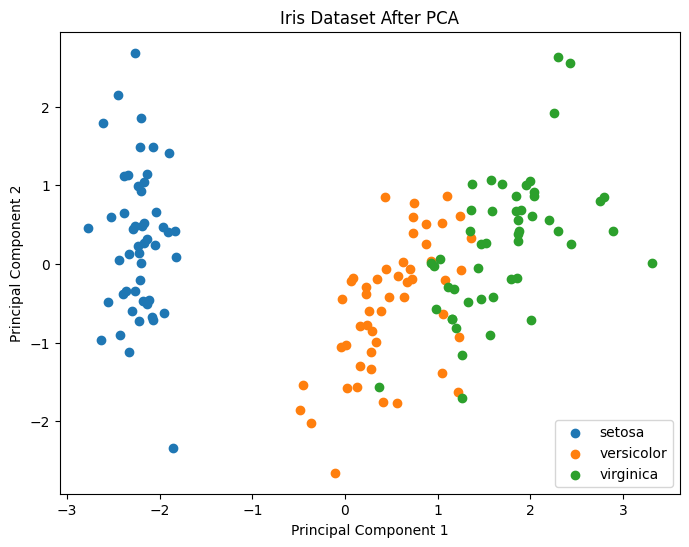

In [ ]:
# Plot the two principal components
plt.figure(figsize=(8, 6))

for class_value, class_name in enumerate(iris.target_names):
    plt.scatter(
        X_pca[y == class_value, 0],
        X_pca[y == class_value, 1],
        label=class_name
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Iris Dataset After PCA")
plt.legend()
plt.show()

## 7. What did PCA actually do?

We started with:

**4 original features**

and transformed them into:

**2 new features**

These new features are:

- Principal Component 1 (PC1)
- Principal Component 2 (PC2)

They are **combinations of the original features**.

PCA did not simply delete two columns.

In [ ]:
# PCA with all components
pca_all = PCA()
X_pca_all = pca_all.fit_transform(X_scaled)

print("Explained variance ratio:")
print(pca_all.explained_variance_ratio_)

print("\nCumulative explained variance:")
print(np.cumsum(pca_all.explained_variance_ratio_))

Explained variance ratio:
[0.72962445 0.22850762 0.03668922 0.00517871]

Cumulative explained variance:
[0.72962445 0.95813207 0.99482129 1.        ]


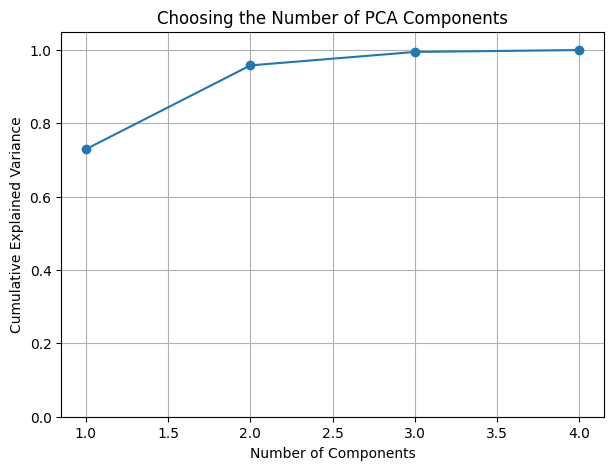

In [ ]:
# Plot cumulative explained variance
plt.figure(figsize=(7, 5))

plt.plot(
    range(1, len(pca_all.explained_variance_ratio_) + 1),
    np.cumsum(pca_all.explained_variance_ratio_),
    marker="o"
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Choosing the Number of PCA Components")
plt.ylim(0, 1.05)
plt.grid(True)
plt.show()

## Important PCA points

1. **PCA reduces dimensionality.**
2. PCA creates **new features**, called principal components.
3. PCA is an **unsupervised** technique.
4. PC1 captures the maximum variance.
5. PC2 captures the next maximum variance and is orthogonal to PC1.
6. Eigenvectors give the principal directions.
7. Eigenvalues indicate the variance associated with those directions.
8. Explained variance helps us decide how many components to keep.
9. Scaling is often important before PCA.
10. PCA does **not always improve model accuracy**.